# [2, 2] KAN symbolic regression: photonic bases with field encoding (√m version)

$y_1 = \sin(4x_1) + x_2^2/2$, $\; y_2 = 0.3x_1^2 + \cos(3x_2)$ on normalised inputs $x \in [0, 1]$. Signed expansion coefficients, no affine map.

**Field-encoding edge model** (update after IPC 2026). For an edge with $m$ photonic bases:

1. $u = \alpha x + \beta$ (affine map), or $u = x$ if no affine map is needed
2. $u/\sqrt{m}$ — 1:$m$ splitter
3. $P = u^2/m$ — optical power entering each FP-LD
4. $b_k(P)$ — analytic FP-LD activation (log/exp/polynomial fit)
5. $\sqrt{b_k(P)}$ — output field amplitude of basis $k$
6. $a_k \sqrt{b_k(P)}$ — expansion coefficient
7. $\varphi(x) = \sum_k a_k \sqrt{b_k(u^2/m)}$; edges are summed at the next node

The input range is chosen so that $P$ covers the same **power window** $[P_{\min}, P_{\max}]$ the bases saw in the May runs,
i.e. $u \in [\sqrt{m P_{\min}}, \sqrt{m P_{\max}}]$. Because every edge has the same $m$, the $1/\sqrt{m}$ factor is absorbed by this choice:
`DIVIDE_BY_M = False` gives identical results.

## Imports

In [1]:
import os

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from scipy.io import savemat, loadmat

from importlib import reload
import kan
reload(kan)

from kan import KAN

## Settings

Only the photonic part differs from the May run (`2_input_2_output_final.ipynb`). Basis selection, data, optimizer, learning rate and epochs are unchanged.

In [2]:
# Photonic bases (same as May / IPC 2026)
selected_indices = np.arange(10)
m = len(selected_indices)            # bases per edge

# Power window seen by the FP-LD: P = x^2/m in [P_MIN, P_MAX]
# (May: the bases were evaluated directly on x in [0, 1])
# P_MIN > 0 adds a constant optical bias to the input (x never reaches 0). Since b(0) = 0 for every
# basis, P_MIN = 0 forces every edge to 0 at x = 0, which y2(x1, 0) = 1 cannot follow.
# Test runs: P_MIN = 0 -> MSE y1 ~ 5e-4, y2 ~ 3e-2;  P_MIN = 0.1 -> y1 ~ 4e-5, y2 ~ 1e-5.
P_MIN, P_MAX = 0.0, 1.0
DIVIDE_BY_M = True                   # 1:m splitter; False gives identical results

# Physical input amplitude range. The target is defined on the normalised input x / x_max_test,
# so the regression task is identical to May.
x_min_test, x_max_test = kan.amplitude_window_from_power_window(P_MIN, P_MAX, m, DIVIDE_BY_M)
# (x_min_test > 0 only when P_MIN > 0)

SEED = 42
n_train = 1000
n_test = 300
num_epochs = 2500
lr = 1e-2

mat_folder = "2-2_sqrtm_exports"
os.makedirs(mat_folder, exist_ok=True)

print(f"m = {m}")
print(f"Power window P = [{P_MIN}, {P_MAX}]  ->  input amplitude x in [{x_min_test:.6f}, {x_max_test:.6f}]")

m = 10
Power window P = [0.0, 1.0]  ->  input amplitude x in [0.000000, 3.162278]


## Load photonic activation

In [3]:
mat_path = "activation_KAN_fit_B_Sofija_extend_positive_basisKAN.mat"

b_coef, input_power, peakout_data, set_detuning = kan.load_photonic_activation_data(mat_path)
b_coef_selected = b_coef[selected_indices]

print("Selected indices:", selected_indices)
print("Selected detunings:", set_detuning[selected_indices])
print("Selected b_coef shape:", b_coef_selected.shape)

Selected indices: [0 1 2 3 4 5 6 7 8 9]
Selected detunings: tensor([-5.0000e+10, -6.0000e+10, -7.0000e+10, -8.0000e+10, -9.0000e+10,
        -1.0000e+11, -1.1000e+11, -1.2000e+11, -1.3000e+11, -1.4000e+11])
Selected b_coef shape: torch.Size([10, 8])


## Data

Same seed and sampling as May; the samples are the May samples mapped onto `[x_min_test, x_max_test]`.

In [4]:
torch.manual_seed(SEED)

# float32 random stream as in May, scaled in float64 so that x never exceeds x_max_test by rounding
x_train = x_min_test + (x_max_test - x_min_test) * torch.rand(n_train, 2).double()
x_test = x_min_test + (x_max_test - x_min_test) * torch.rand(n_test, 2).double()

def target_fn(x):
    # normalised inputs in [0, 1] (identical to May when P_MIN = 0)
    x1n = (x[:, 0:1] - x_min_test) / (x_max_test - x_min_test)
    x2n = (x[:, 1:2] - x_min_test) / (x_max_test - x_min_test)

    y1 = torch.sin(4.0 * x1n) + 0.5 * x2n**2
    y2 = 0.3 * x1n**2 + torch.cos(3.0 * x2n)

    return torch.cat([y1, y2], dim=1)

y_train = target_fn(x_train)
y_test = target_fn(x_test)

## KAN model

In [5]:
model = KAN(
    in_count=2,
    out_count=2,
    hidden_layer_sizes=[],
    layer_type="photonic",
    b_coef_selected=b_coef_selected,
    x_min=x_min_test,
    x_max=x_max_test,
    dropout_prob=0.0,
    normalize_basis=False,
    check_input_range=True,
    debug=False,
    field_encoding=True,
    divide_by_m=DIVIDE_BY_M,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device=device, dtype=torch.float64)

x_train = x_train.to(device=device, dtype=torch.float64)
y_train = y_train.to(device=device, dtype=torch.float64)
x_test = x_test.to(device=device, dtype=torch.float64)
y_test = y_test.to(device=device, dtype=torch.float64)

# Range check of the photonic chain before training
with torch.no_grad():
    _, stats = model(x_train, track_stats=True)
s = stats[0]
print(f"x  in [{s['min_input'].item():.4f}, {s['max_input'].item():.4f}]")
print(f"P  in [{s['min_P'].item():.4f}, {s['max_P'].item():.4f}]   (FP-LD input power)")
print(f"b  in [{s['min_b'].item():.4f}, {s['max_b'].item():.4f}]")
print(f"sqrt(b) in [{s['min_basis'].item():.4f}, {s['max_basis'].item():.4f}]")

x  in [0.0074, 3.1617]
P  in [0.0000, 0.9996]   (FP-LD input power)
b  in [0.0000, 5.8340]
sqrt(b) in [0.0000, 2.4154]


## Training

In [6]:
optimizer = optim.Adam(model.parameters(), lr=lr)
loss_fn = nn.MSELoss()

train_losses = []
test_losses = []

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = loss_fn(y_pred, y_train)
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        y_test_pred = model(x_test)
        test_loss = loss_fn(y_test_pred, y_test)

    train_losses.append(loss.item())
    test_losses.append(test_loss.item())

    if epoch % 250 == 0 or epoch == num_epochs - 1:
        print(f"Epoch {epoch:4d} | train loss = {loss.item():.6f} | test loss = {test_loss.item():.6f}")

Epoch    0 | train loss = 0.559008 | test loss = 0.451271
Epoch  250 | train loss = 0.025187 | test loss = 0.024544
Epoch  500 | train loss = 0.020738 | test loss = 0.019998
Epoch  750 | train loss = 0.018894 | test loss = 0.018119
Epoch 1000 | train loss = 0.017848 | test loss = 0.017011
Epoch 1250 | train loss = 0.017145 | test loss = 0.016249
Epoch 1500 | train loss = 0.016611 | test loss = 0.015668
Epoch 1750 | train loss = 0.016176 | test loss = 0.015193
Epoch 2000 | train loss = 0.015808 | test loss = 0.014788
Epoch 2250 | train loss = 0.015510 | test loss = 0.014448
Epoch 2499 | train loss = 0.015289 | test loss = 0.014207


## Final MSE (per output, as reported in the abstract)

In [7]:
model.eval()
with torch.no_grad():
    y_pred_train = model(x_train)
    y_pred_test = model(x_test)

mse_train_per_output = ((y_pred_train - y_train) ** 2).mean(dim=0).cpu().numpy()
mse_test_per_output = ((y_pred_test - y_test) ** 2).mean(dim=0).cpu().numpy()

print(f"Train MSE  y1 = {mse_train_per_output[0]:.3e} | y2 = {mse_train_per_output[1]:.3e} | mean = {mse_train_per_output.mean():.3e}")
print(f"Test  MSE  y1 = {mse_test_per_output[0]:.3e} | y2 = {mse_test_per_output[1]:.3e} | mean = {mse_test_per_output.mean():.3e}")

Train MSE  y1 = 5.219e-04 | y2 = 3.005e-02 | mean = 1.529e-02
Test  MSE  y1 = 4.553e-04 | y2 = 2.796e-02 | mean = 1.421e-02


## Loss curves and true vs predicted

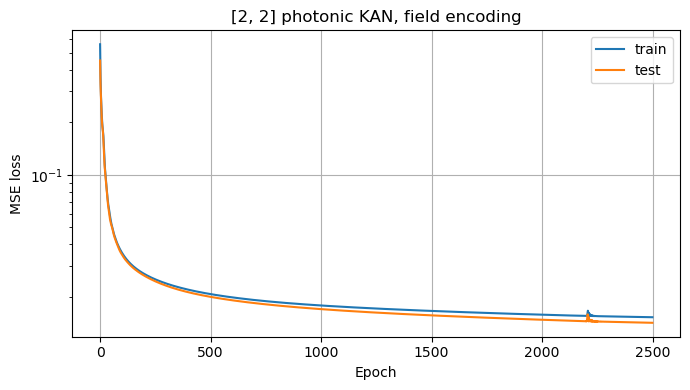

In [8]:
savemat(os.path.join(mat_folder, "loss_curves.mat"), {
    "plot_type": "loss_curves",
    "epoch": np.arange(num_epochs),
    "train_losses": np.array(train_losses),
    "test_losses": np.array(test_losses),
    "num_epochs": num_epochs,
})

plt.figure(figsize=(7, 4))
plt.semilogy(train_losses, label="train")
plt.semilogy(test_losses, label="test")
plt.xlabel("Epoch"); plt.ylabel("MSE loss")
plt.title("[2, 2] photonic KAN, field encoding")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

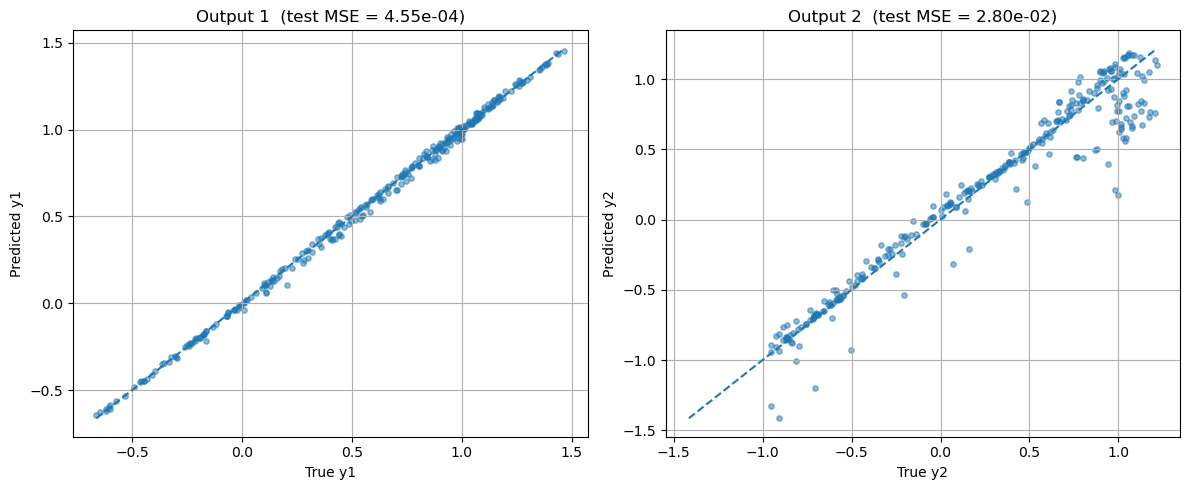

In [9]:
savemat(os.path.join(mat_folder, "true_vs_pred_test.mat"), {
    "plot_type": "true_vs_pred_test",
    "x_test": x_test.detach().cpu().numpy(),
    "x_test_normalized": ((x_test - x_min_test) / (x_max_test - x_min_test)).detach().cpu().numpy(),
    "y_test": y_test.detach().cpu().numpy(),
    "y_pred_test": y_pred_test.detach().cpu().numpy(),
    "mse_test_per_output": mse_test_per_output,
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for j in range(2):
    yt = y_test[:, j].cpu().numpy(); yp = y_pred_test[:, j].cpu().numpy()
    axes[j].scatter(yt, yp, alpha=0.5, s=15)
    lo, hi = min(yt.min(), yp.min()), max(yt.max(), yp.max())
    axes[j].plot([lo, hi], [lo, hi], linestyle="--")
    axes[j].set_xlabel(f"True y{j+1}"); axes[j].set_ylabel(f"Predicted y{j+1}")
    axes[j].set_title(f"Output {j+1}  (test MSE = {mse_test_per_output[j]:.2e})")
    axes[j].grid(True)
plt.tight_layout(); plt.show()

## Basis functions, edge functions, coefficient vectors

x axis = physical input amplitude $x \in [\sqrt{m P_{\min}}, \sqrt{m P_{\max}}]$. The basis is the effective basis $\sqrt{b_k(x^2/m)}$; `.mat` files also contain `P` and `b_raw`.

Saved MATLAB plot data to: 2-2_sqrtm_exports/basis_L0_in0.mat


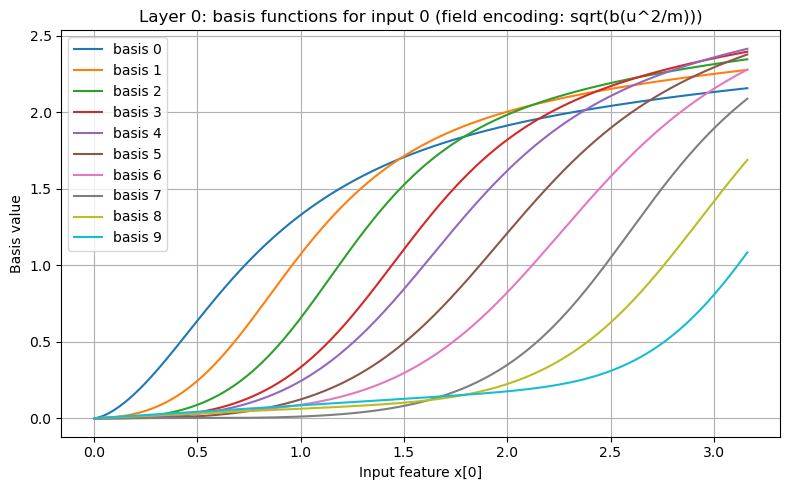

Saved MATLAB plot data to: 2-2_sqrtm_exports/basis_L0_in1.mat


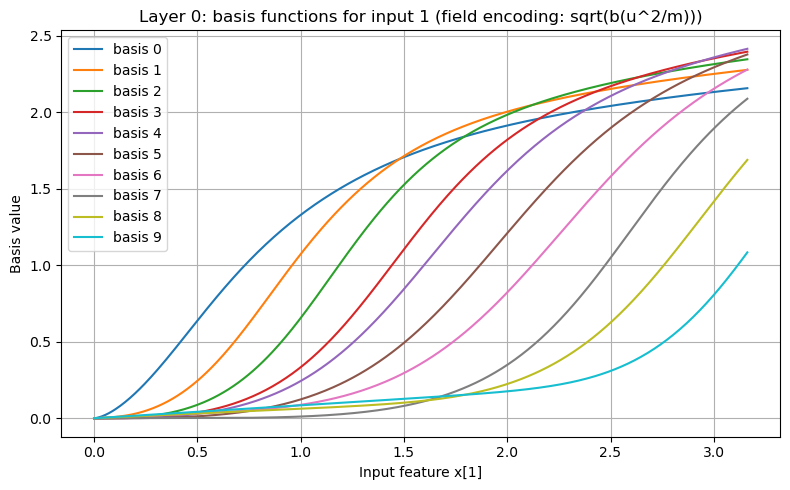

basis shape: torch.Size([400, 10])
basis finite: True
phi finite: True
Saved MATLAB plot data to: 2-2_sqrtm_exports/edge_L0_out0_in0.mat


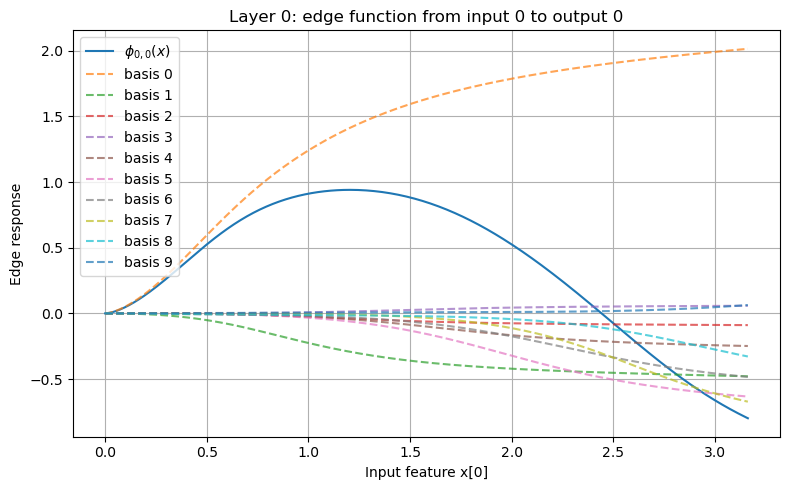

basis shape: torch.Size([400, 10])
basis finite: True
phi finite: True
Saved MATLAB plot data to: 2-2_sqrtm_exports/edge_L0_out0_in1.mat


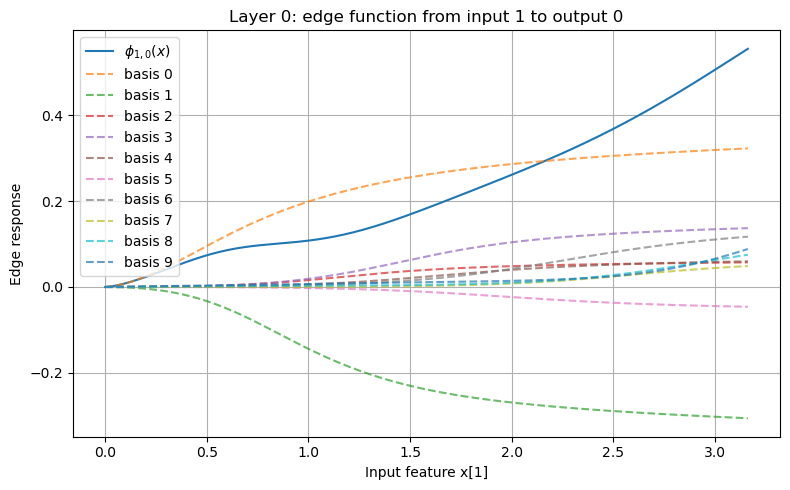

basis shape: torch.Size([400, 10])
basis finite: True
phi finite: True
Saved MATLAB plot data to: 2-2_sqrtm_exports/edge_L0_out1_in0.mat


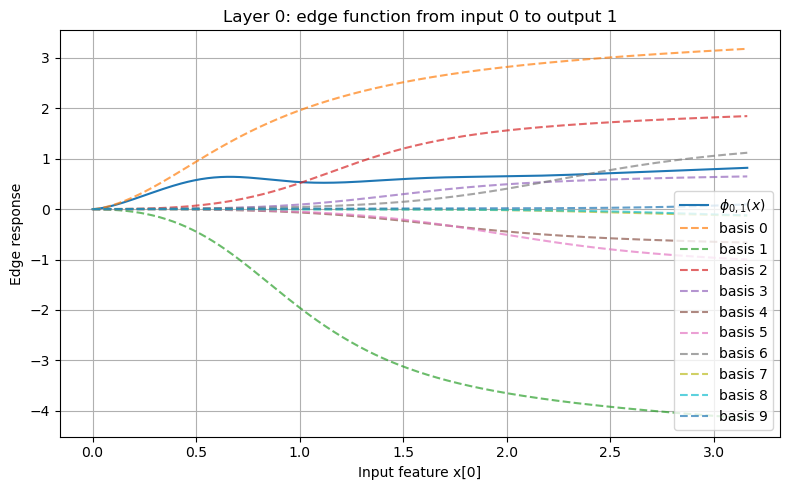

basis shape: torch.Size([400, 10])
basis finite: True
phi finite: True
Saved MATLAB plot data to: 2-2_sqrtm_exports/edge_L0_out1_in1.mat


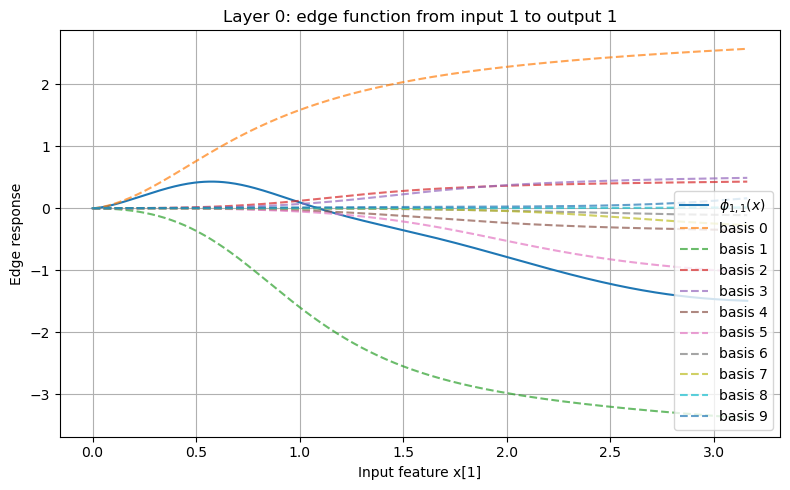

In [10]:
model.plot_basis_functions(layer_idx=0, in_idx=0, x_range=(x_min_test, x_max_test), mat_export_path="basis_L0_in0.mat", mat_export_dir=mat_folder)
model.plot_basis_functions(layer_idx=0, in_idx=1, x_range=(x_min_test, x_max_test), mat_export_path="basis_L0_in1.mat", mat_export_dir=mat_folder)

for out_idx in range(2):
    for in_idx in range(2):
        model.plot_edge_function(
            layer_idx=0, out_idx=out_idx, in_idx=in_idx,
            x_range=(x_min_test, x_max_test), show_basis=True,
            mat_export_path=f"edge_L0_out{out_idx}_in{in_idx}.mat", mat_export_dir=mat_folder,
        )

Saved MATLAB plot data to: 2-2_sqrtm_exports/coeff_vector_L0_out0_in0.mat


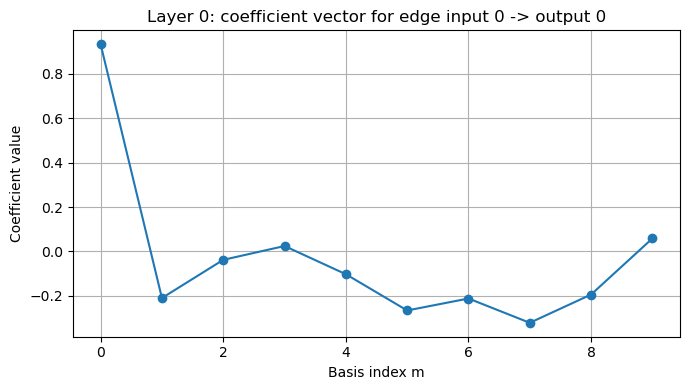

Saved MATLAB plot data to: 2-2_sqrtm_exports/coeff_vector_L0_out0_in1.mat


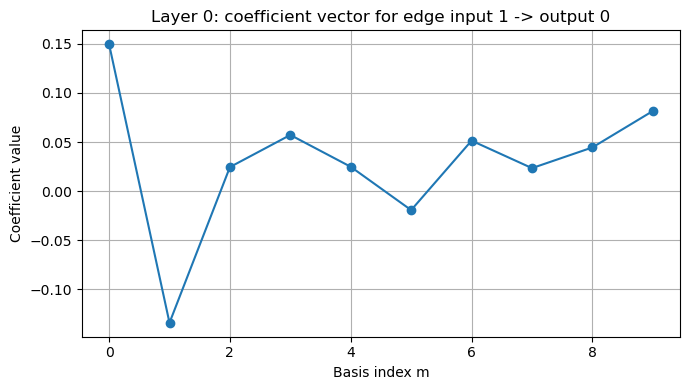

Saved MATLAB plot data to: 2-2_sqrtm_exports/coeff_vector_L0_out1_in0.mat


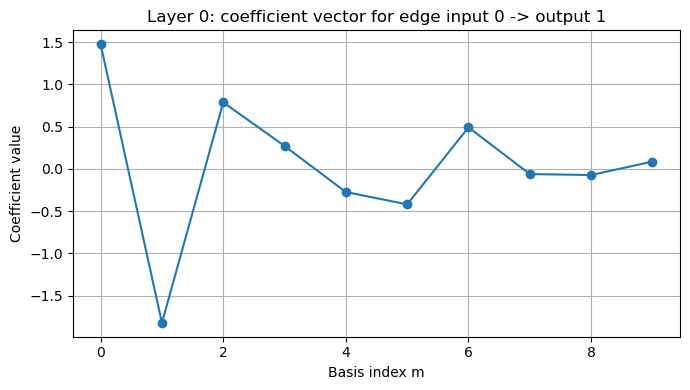

Saved MATLAB plot data to: 2-2_sqrtm_exports/coeff_vector_L0_out1_in1.mat


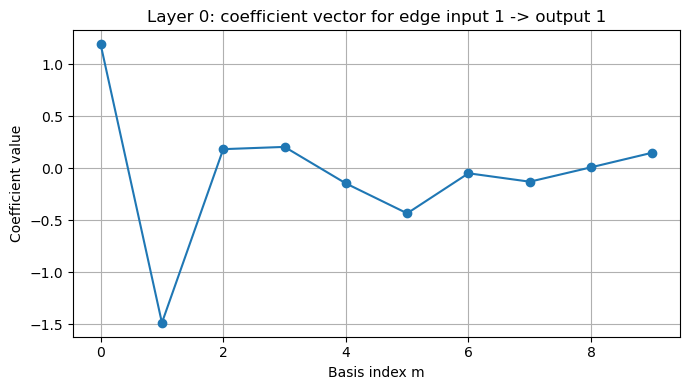

In [11]:
for out_idx in range(2):
    for in_idx in range(2):
        model.plot_coefficient_vector(
            layer_idx=0, out_idx=out_idx, in_idx=in_idx,
            mat_export_path=f"coeff_vector_L0_out{out_idx}_in{in_idx}.mat", mat_export_dir=mat_folder,
        )

## Target approximation along one input (other input fixed at normalised 0.5)

Saved MATLAB plot data to: 2-2_sqrtm_exports/target_approx_varied_x0.mat


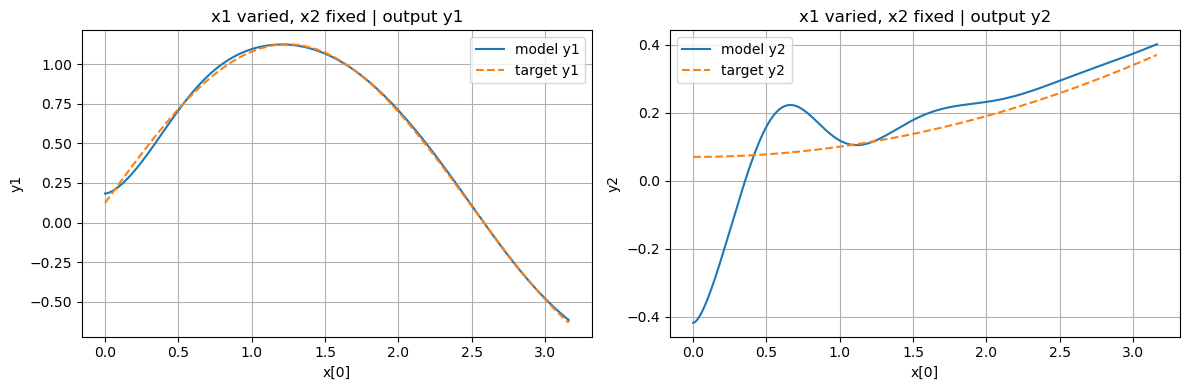

Saved MATLAB plot data to: 2-2_sqrtm_exports/target_approx_varied_x1.mat


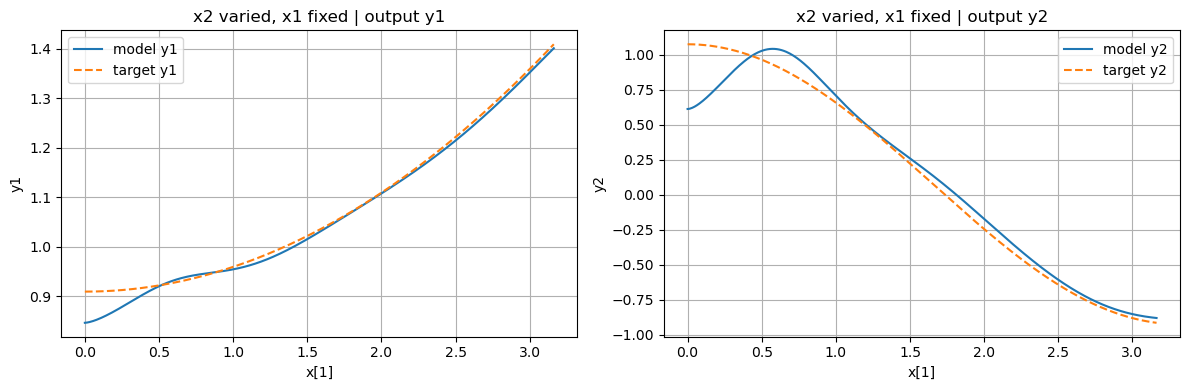

In [12]:
model.plot_target_approximation(
    target_fn=target_fn,
    x_range=(x_min_test, x_max_test),
    fixed_values=[0.5 * (x_min_test + x_max_test), 0.5 * (x_min_test + x_max_test)],
    mat_export_prefix="target_approx",
    mat_export_dir=mat_folder,
)

## Full forward pass export (MATLAB) and independent NumPy check

In [13]:
extra = {
    "model_description": "[2,2] photonic KAN, field encoding: edge = sum_k a_k sqrt(b_k(x^2/m))",
    "target": "y1 = sin(4*x1n) + 0.5*x2n^2; y2 = 0.3*x1n^2 + cos(3*x2n); xn = (x - x_min) / (x_max - x_min)",
    "power_window": np.array([P_MIN, P_MAX]),
    "input_amplitude_range": np.array([x_min_test, x_max_test]),
    "selected_indices_python": selected_indices,
    "selected_indices_matlab": selected_indices + 1,
    "selected_detunings": set_detuning[selected_indices],
    "x_test": x_test, "y_test": y_test, "y_pred_test": y_pred_test,
    "mse_test_per_output": mse_test_per_output, "mse_train_per_output": mse_train_per_output,
    "seed": SEED, "num_epochs": num_epochs, "lr": lr,
}

err = kan.export_full_forward_to_mat(
    model, x_test,
    os.path.join(mat_folder, "photonic_kan_2-2_sqrtm_full_forward_test.mat"),
    extra=extra,
)
assert err < 1e-8, "PyTorch and NumPy forward passes disagree"

Saved full forward pass to: 2-2_sqrtm_exports/photonic_kan_2-2_sqrtm_full_forward_test.mat
Max |PyTorch - NumPy| = 9.992e-16  (relative to max |y|: 6.866e-16)


## Comparison with the May (IPC 2026) result

In [14]:
old_path = os.path.join("results_v1_IPC2026", "2-2_exports", "true_vs_pred_test.mat")
if os.path.exists(old_path):
    old = loadmat(old_path, squeeze_me=True)
    old_mse = ((old["y_pred_test"] - old["y_test"]) ** 2).mean(axis=0)
else:
    old_mse = np.array([1e-5, 7e-3])  # values reported in the abstract

print(f"{'Test MSE':12s}{'May (b(x))':>14s}{'new (sqrt(b(x^2/m)))':>24s}")
for j in range(2):
    print(f"{'y' + str(j + 1):12s}{old_mse[j]:>14.3e}{mse_test_per_output[j]:>24.3e}")

Test MSE        May (b(x))    new (sqrt(b(x^2/m)))
y1               1.042e-05               4.553e-04
y2               6.984e-03               2.796e-02
